## LTV и юнит-экономика

На лекции мы прошли путь от маржи одного заказа до прибыли компании. На семинаре пройдем его на данных: по шагам посчитаем LTV, соберем из когорт P&L и разберем, как пользоваться LTV для решений, когда нужных данных еще нет.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 17, 'axes.labelsize': 14, 'axes.titlepad': 16,
    'figure.figsize': (11, 5), 'axes.spines.top': False, 'axes.spines.right': False,
})

import warnings
warnings.filterwarnings('ignore')

### Данные

Сервис доставки еды, 2025 год, 12 месячных когорт. Три таблицы:
- df_users — пользователи: месяц первого заказа и канал привлечения;
- df_orders — заказы с выручкой и расходами;
- df_costs — рекламные расходы по каналам и месяцам.

Постоянные расходы компании — 1.5 млн руб в месяц.

Данные синтетические. Внутри генератора у каждого пользователя есть скрытая вероятность уйти из сервиса, поэтому генератор знает, сколько в среднем принесет пользователь каждого канала за пять лет.

Таблицу (`df_truth`) мы посмотрим только в конце.

In [2]:
def generate_ltv_data(seed=42):
    rng = np.random.default_rng(seed)
    months = [f'2025-{m:02d}' for m in range(1, 13)]

    spec = {
        'organic':     dict(n=1500, a=1.0, b=2.5, lam=2.6, cac=0,   promo=0.0),
        'search_ads':  dict(n=1200, a=0.9, b=3.0, lam=2.8, cac=420, promo=0.3),
        'social_ads':  dict(n=1300, a=1.3, b=1.7, lam=2.0, cac=280, promo=0.5),
        'display_ads': dict(n=800,  a=3.0, b=1.2, lam=2.2, cac=110, promo=0.9),
    }

    users, orders, costs, lives, uid = [], [], [], {ch: [] for ch in spec}, 0
    for c, month in enumerate(months):
        for ch, p in spec.items():
            n = int(p['n'] * rng.uniform(0.92, 1.08))
            ids = np.arange(uid, uid + n)
            uid += n

            life = rng.geometric(rng.beta(p['a'], p['b'], n))
            lives[ch].append(life)
            has_promo = rng.random(n) < p['promo']

            users.append(pd.DataFrame({'user_id': ids, 'cohort_month': month, 'channel': ch}))
            costs.append({'month': month, 'channel': ch, 'ad_spend': round(n * p['cac'] * rng.normal(1, 0.03))})

            for age in range(12 - c):
                k = rng.poisson(p['lam'], n) * (life > age) if age > 0 else 1 + rng.poisson(p['lam'] - 1, n)
                o = pd.DataFrame({'user_id': np.repeat(ids, k), 'order_month': months[c + age]})
                o['is_first'] = False
                o['promo_first_order'] = 0.0
                if age == 0:
                    o.loc[np.cumsum(k) - k, 'is_first'] = True
                    o['promo_first_order'] = np.where(o.is_first & np.repeat(has_promo, k), 200.0, 0.0)
                orders.append(o)

    df_users = pd.concat(users, ignore_index=True)
    df_orders = pd.concat(orders, ignore_index=True)
    m = len(df_orders)
    df_orders['gmv'] = rng.lognormal(np.log(900), 0.45, m).round(0)
    df_orders['revenue'] = (0.25 * df_orders.gmv).round(2)
    df_orders['courier_cost'] = rng.normal(140, 15, m).clip(80).round(2)
    df_orders['payment_fee'] = (0.02 * df_orders.gmv).round(2)
    df_orders['compensation_cost'] = np.where(rng.random(m) < 0.10, 150.0, 0.0)
    df_orders['promo_retention'] = np.where(~df_orders.is_first & (rng.random(m) < 0.08), 150.0, 0.0)
    is_first = df_orders.pop('is_first').to_numpy()
    df_orders.insert(0, 'order_id', np.arange(m))
    df_orders = df_orders[['order_id', 'user_id', 'order_month', 'gmv', 'revenue', 'courier_cost',
                           'payment_fee', 'compensation_cost', 'promo_retention', 'promo_first_order']]

    cm = (df_orders.revenue - df_orders.courier_cost - df_orders.payment_fee
          - df_orders.compensation_cost - df_orders.promo_retention).to_numpy()
    cm_first, cm_repeat = cm[is_first].mean(), cm[~is_first].mean()
    truth = {}
    for ch, p in spec.items():
        life = np.concatenate(lives[ch])
        alive = np.array([(life > k).mean() for k in range(60)])
        per_age = p['lam'] * cm_repeat * alive
        per_age[0] = cm_first + (p['lam'] - 1) * cm_repeat
        truth[ch] = np.cumsum(per_age)
    df_truth = pd.DataFrame(truth).rename_axis('age')

    return df_users, df_orders, pd.DataFrame(costs), df_truth

In [3]:
df_users, df_orders, df_costs, df_truth = generate_ltv_data()

In [4]:
FIXED_COSTS = 1500000  

print(f'Пользователей: {len(df_users):};  заказов: {len(df_orders):};  '
      f'средний чек: {df_orders.gmv.mean():.0f} руб')

Пользователей: 57933;  заказов: 420044;  средний чек: 996 руб


In [5]:
df_users.head()

,user_id,cohort_month,channel
0,0,2025-01,organic
1,1,2025-01,organic
2,2,2025-01,organic
3,3,2025-01,organic
4,4,2025-01,organic


In [6]:
df_orders.head()

,order_id,user_id,order_month,gmv,revenue,courier_cost,payment_fee,compensation_cost,promo_retention,promo_first_order
0,0,0,2025-01,1109.0,277.25,133.04,22.18,150.0,0.0,0.0
1,1,0,2025-01,1372.0,343.00,137.92,27.44,0.0,0.0,0.0
2,2,0,2025-01,613.0,153.25,115.39,12.26,150.0,0.0,0.0
3,3,0,2025-01,1393.0,348.25,104.44,27.86,0.0,0.0,0.0
4,4,0,2025-01,837.0,209.25,143.79,16.74,0.0,0.0,0.0


In [7]:
df_costs.head()

,month,channel,ad_spend
0,2025-01,organic,0
1,2025-01,search_ads,510530
2,2025-01,social_ads,350958
3,2025-01,display_ads,89095
4,2025-02,organic,0


### Шаг 1. Маржа заказа

LTV считают по маржинальной прибыли, поэтому сначала нужна маржа каждого заказа — выручка минус расходы, которые появляются вместе с заказом:

$$
\text{CM} = \text{Revenue} - \text{Courier\_Cost} - \text{Payment\_Fee} - \text{Compensation\_Cost} - \text{Promo\_Retention}
$$

- `courier_cost` и `payment_fee` — себестоимость: без курьера и эквайринга заказ не исполнить;
- `compensation_cost` — компенсация клиенту за проблемный заказ;
- `promo_retention` — промокод постоянному клиенту.

Столбец `promo_first_order` не вычитаем. Промокод на первый заказ выдается один раз, чтобы пользователь появился, — это расход на привлечение, и **он войдет в CAC**.

In [8]:
df_orders['cm'] = (df_orders.revenue - df_orders.courier_cost - df_orders.payment_fee
                   - df_orders.compensation_cost - df_orders.promo_retention)

order_avg = df_orders[['gmv', 'revenue', 'courier_cost', 'payment_fee',
                       'compensation_cost', 'promo_retention', 'cm']].mean()

order_avg.round(1).to_frame('руб на заказ').T

,gmv,revenue,courier_cost,payment_fee,compensation_cost,promo_retention,cm
руб на заказ,996.1,249.0,140.0,19.9,15.0,10.4,63.7


In [9]:
round(order_avg['cm'] / order_avg['gmv'] * 100, 1)

6.4

Клиент платит в среднем 996 руб, сервису остается 249 руб выручки и 64 руб маржи — 6.4% оборота.

### Шаг 2. Когорта и возраст

**Когорта** — пользователи, сделавшие первый заказ в одном месяце. **Возраст** когорты в календарном месяце — сколько месяцев прошло с месяца когорты: в месяц первого заказа возраст равен 0.

Каждый заказ относим к когорте пользователя и к возрасту, на котором когорта была в месяц заказа. Так заказы разных когорт можно сравнивать: январская и июльская когорты на возрасте 3 находятся в одной точке жизни, хотя календарные месяцы у них разные.

In [10]:
month_idx = {m: i for i, m in enumerate(sorted(df_orders.order_month.unique()))}
LAST = max(month_idx.values())

df = df_orders.merge(df_users, on='user_id')
df['age'] = df.order_month.map(month_idx) - df.cohort_month.map(month_idx)

In [11]:
(df[df.user_id == 159].groupby(['user_id', 'cohort_month', 'order_month', 'age'])
 .agg(orders=('order_id', 'size'), cm=('cm', 'sum')).round().reset_index())

,user_id,cohort_month,order_month,age,orders,cm
0,159,2025-01,2025-01,0,1,50.0
1,159,2025-01,2025-02,1,1,115.0
2,159,2025-01,2025-03,2,2,674.0
3,159,2025-01,2025-04,3,1,254.0
4,159,2025-01,2025-05,4,3,-223.0


In [12]:
df[(df.user_id == 159) & (df.age == 4)]

,order_id,user_id,order_month,gmv,revenue,courier_cost,payment_fee,compensation_cost,promo_retention,promo_first_order,cm,cohort_month,channel,age
11420,11420,159,2025-05,567.0,141.75,159.41,11.34,0.0,0.0,0.0,-29.00,2025-01,organic,4
11421,11421,159,2025-05,335.0,83.75,117.47,6.70,0.0,0.0,0.0,-40.42,2025-01,organic,4
11422,11422,159,2025-05,525.0,131.25,124.47,10.50,0.0,150.0,0.0,-153.72,2025-01,organic,4


Пользователь пришел в январе и заказывал пять месяцев подряд, после мая заказов нет. Для LTV важны обе части этой истории: сколько маржи он принес, пока был с нами, и то, что после возраста 4 он приносит ноль.

### Шаг 3. Когортная матрица

Делим маржу когорты на возрасте $k$ на **размер когорты** — число привлеченных пользователей:

$$
m_{c,k} = \frac{\text{маржа когорты } c \text{ на возрасте } k}{N_c}
$$

В знаменателе все, кого привлекли, включая ушедших. Мы отвечаем на вопрос «сколько приносит привлеченный пользователь», а не «сколько приносит оставшийся».

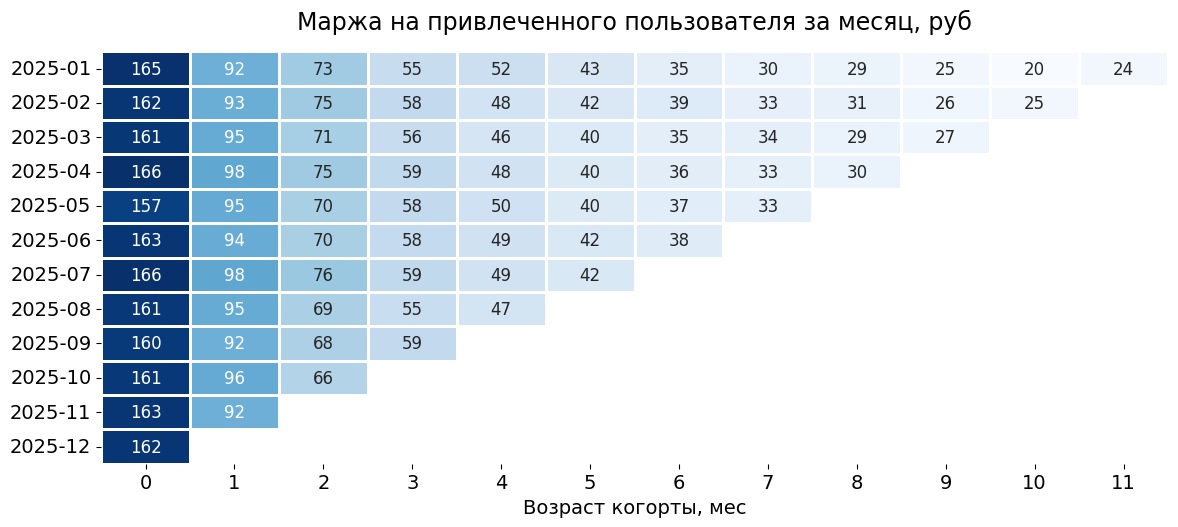

In [13]:
cohort_size = df_users.groupby('cohort_month').user_id.size()

cm_matrix = df.pivot_table(index='cohort_month', columns='age', values='cm', aggfunc='sum')
margin_matrix = cm_matrix.div(cohort_size, axis=0)

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(margin_matrix, annot=True, fmt='.0f', cmap='Blues', cbar=False, linewidths=1, ax=ax, annot_kws={'size': 12})
ax.set_title('Маржа на привлеченного пользователя за месяц, руб')
ax.set_xlabel('Возраст когорты, мес'); ax.set_ylabel('')
plt.tight_layout()
plt.show()

Строка — когорта, столбец — возраст. Матрица треугольная: январская когорта прожила 12 месяцев, декабрьская — один.

- **В первый месяц пользователь приносит около 160 руб**, во второй — уже около 95, к двенадцатому — около 25. Активные пользователи заказывают столько же, но их становится меньше.
- **Когорты похожи друг на друга:** в столбце возраста 0 значения от 157 до 166 руб. Значит, их можно усреднять.

Накопим маржу по возрасту — получим LTV каждой когорты.

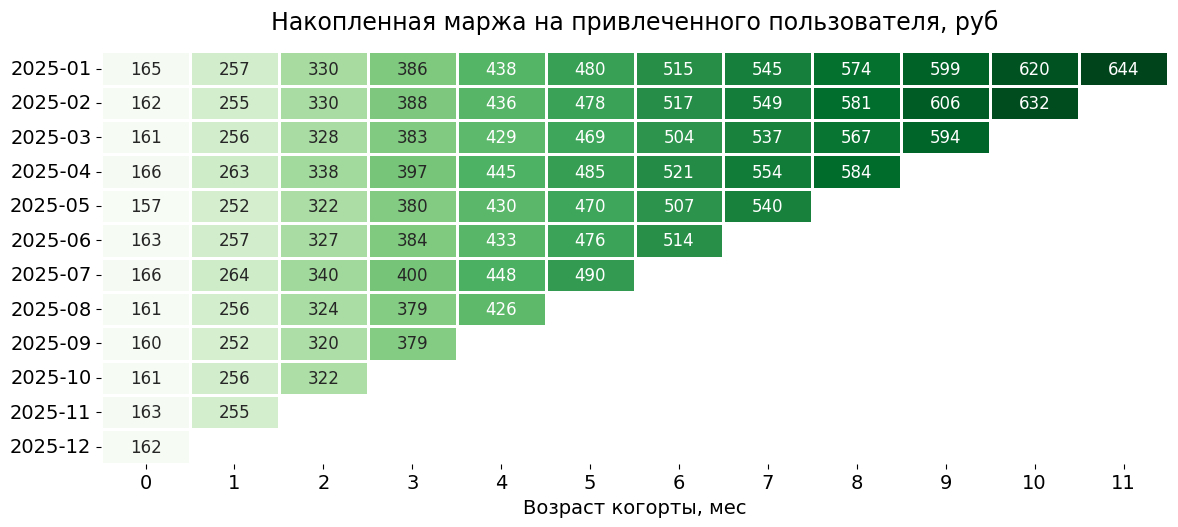

In [14]:
ltv_matrix = margin_matrix.cumsum(axis=1)

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(ltv_matrix, annot=True, fmt='.0f', cmap='Greens', cbar=False, linewidths=1, ax=ax, annot_kws={'size': 12})
ax.set_title('Накопленная маржа на привлеченного пользователя, руб')
ax.set_xlabel('Возраст когорты, мес'); ax.set_ylabel('')
plt.tight_layout()
plt.show()

Январская когорта за 12 месяцев принесла 644 руб на привлеченного пользователя. Про июльскую мы знаем только первые шесть месяцев — 490 руб; что будет дальше, в данных еще нет.

### Шаг 4. Кривая LTV

Чтобы получить одну кривую, усредним когорты. На каждом возрасте берем маржу всех когорт и делим на число пользователей **тех когорт, которые до этого возраста дожили**:

$$
m_k = \frac{\sum_{c:\ \text{когорта дожила до } k} \text{маржа}_{c,k}}{\sum_{c:\ \text{когорта дожила до } k} N_c}, \qquad \text{LTV}_k = \sum_{j=0}^{k} m_j
$$

In [15]:
def margin_by_age(df, df_users, last=LAST):
    d = df[df.order_month.map(month_idx) <= last]
    u = df_users[df_users.cohort_month.map(month_idx) <= last]
    max_age = last - u.cohort_month.map(month_idx)
    margin = [d[d.age == k].cm.sum() / (max_age >= k).sum() for k in range(last + 1)]
    
    return pd.Series(margin, index=pd.RangeIndex(last + 1, name='age'))


def margin_by_age_wrong(df, df_users):
    margin = [df[df.age == k].cm.sum() / len(df_users) for k in range(LAST + 1)]
    
    return pd.Series(margin, index=pd.RangeIndex(LAST + 1, name='age'))

In [16]:
margin_all = margin_by_age(df, df_users)
ltv_all = margin_all.cumsum()
ltv_wrong = margin_by_age_wrong(df, df_users).cumsum()

pd.DataFrame({'margin': margin_all, 'ltv': ltv_all, 'ltv_wrong': ltv_wrong}).round(0).astype(int).T

age,0,1,2,3,4,5,6,7,8,9,10,11
margin,162,95,71,57,48,41,36,33,30,26,23,24
ltv,162,257,328,385,434,475,511,544,574,600,623,647
ltv_wrong,162,249,308,351,383,407,426,439,449,456,460,462


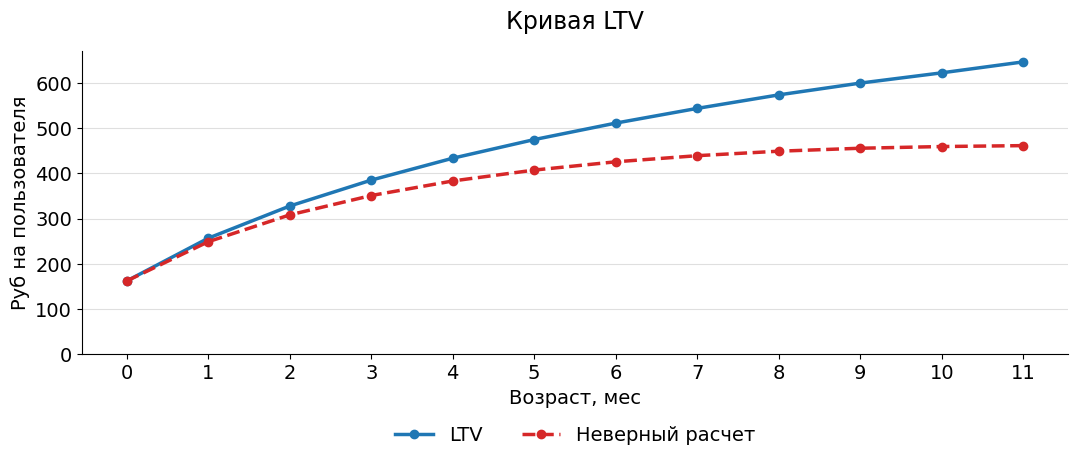

In [17]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(ltv_all.index, ltv_all, marker='o', lw=2.5, color='#1f77b4', label='LTV')
ax.plot(ltv_wrong.index, ltv_wrong, marker='o', lw=2.5, ls='--', color='#d62728', label='Неверный расчет')
ax.set_title('Кривая LTV')
ax.set_xlabel('Возраст, мес'); ax.set_ylabel('Руб на пользователя')
ax.set_xticks(range(12)); ax.set_ylim(0)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

In [18]:
print(f'Неверный расчет на возрасте 11 ниже на {1 - ltv_wrong[11] / ltv_all[11]:.0%}')

Неверный расчет на возрасте 11 ниже на 29%


На возрасте 0 расчеты совпадают: его прожили все когорты. Дальше усреднение по всем пользователям отстает, и к возрасту 11 результат ниже на 29%.

На возрасте 11 маржу принесла только январская когорта, а наивный расчет делит ее на пользователей всех двенадцати. Одиннадцать когорт попали в знаменатель, хотя еще не могли сделать заказ на этом возрасте. Мы не знаем, что они сделают, и считать это нулем нельзя.

**LTV за 12 месяцев — 647 руб на привлеченного пользователя.**

### Шаг 5. CAC и окупаемость

Сравним LTV со стоимостью привлечения. Считаем юнит-экономику всего бизнеса, поэтому берем все расходы на привлечение и всех новых пользователей, включая органику:

$$
\text{CAC} = \frac{\text{реклама} + \text{промокоды на первый заказ}}{\text{все новые пользователи}}
$$

**Срок окупаемости** — первый возраст, на котором LTV покрывает CAC.

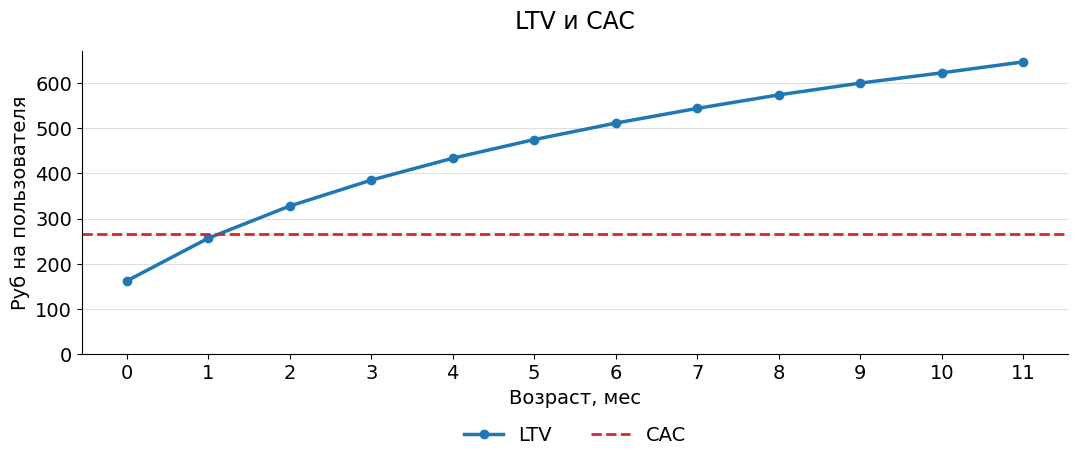

In [19]:
acquisition = df_costs.ad_spend.sum() + df.promo_first_order.sum()
cac = acquisition / len(df_users)
payback = ltv_all[ltv_all >= cac].index[0]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(ltv_all.index, ltv_all, marker='o', lw=2.5, color='#1f77b4', label='LTV')
ax.axhline(cac, color='#d62728', ls='--', lw=2, label='CAC')
ax.set_title('LTV и CAC')
ax.set_xlabel('Возраст, мес'); ax.set_ylabel('Руб на пользователя')
ax.set_xticks(range(12)); ax.set_ylim(0)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

In [20]:
print(f'CAC: {cac:.0f} руб;  LTV за 12 месяцев: {ltv_all[11]:.0f} руб;  LTV / CAC: {ltv_all[11] / cac:.1f}')
print(f'Окупаемость: возраст {payback}, то есть {payback + 1}-й месяц жизни')

CAC: 267 руб;  LTV за 12 месяцев: 647 руб;  LTV / CAC: 2.4
Окупаемость: возраст 2, то есть 3-й месяц жизни


Привлечение пользователя стоит 267 руб, за год он приносит 647 руб — в 2.4 раза больше. Затраты возвращаются на третий месяц жизни.

**Юнит-экономика положительна: каждый привлеченный пользователь окупается с большим запасом.**

### От LTV к P&L

**Если каждый пользователь окупается за три месяца, значит ли это, что компания в 2025 году заработала?**

Прибыль месяца $t$ складывается из маржи всех когорт в этом месяце за вычетом расходов на привлечение и постоянных расходов:

$$
\Pi_t = \sum_{c \le t} N_c \cdot m_{c,\,t-c} \;-\; A_t \;-\; FC
$$

где $A_t$ — расходы на привлечение в месяце $t$, $FC$ — постоянные расходы.

#### Одна когорта

Сначала посмотрим, как в P&L выглядит одна январская когорта: ее маржа по календарным месяцам и расходы на ее привлечение. Значения в млн руб.

In [21]:
jan = df[df.cohort_month == '2025-01']
jan_acquisition = (df_costs[df_costs.month == '2025-01'].ad_spend.sum() + jan.promo_first_order.sum())

one = jan.groupby('order_month').cm.sum().to_frame('margin')
one['acquisition'] = 0.0
one.loc['2025-01', 'acquisition'] = jan_acquisition
one['contribution'] = one.margin - one.acquisition
one['cumulative'] = one.contribution.cumsum()

(one / 1000000).round(2).T

order_month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
margin,0.8,0.45,0.35,0.27,0.25,0.21,0.17,0.15,0.14,0.12,0.10,0.12
acquisition,1.3,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
contribution,-0.5,0.45,0.35,0.27,0.25,0.21,0.17,0.15,0.14,0.12,0.10,0.12
cumulative,-0.5,-0.06,0.30,0.56,0.81,1.02,1.19,1.33,1.47,1.60,1.69,1.81


- **В январе когорта убыточна:** принесла 0.80 млн руб маржи, а на привлечение ушло 1.30 млн.
- **Дальше она каждый месяц в плюсе:** расходов на нее больше нет, а маржа продолжает приходить.
- **Накопленный вклад выходит в плюс в марте** — это тот же срок окупаемости, что на шаге 5. К декабрю когорта заработала 1.81 млн руб.

LTV когорты попадает в P&L по частям, месяц за месяцем, а CAC — целиком в первый месяц.

#### Все когорты

Теперь сложим все когорты и вычтем постоянные расходы.

In [22]:
layers = df.pivot_table(index='cohort_month', columns='order_month', values='cm', aggfunc='sum').fillna(0)

pnl = pd.DataFrame({
    'margin': layers.sum(),
    'acquisition': df_costs.groupby('month').ad_spend.sum() + df.groupby('order_month').promo_first_order.sum(),
    'fixed': FIXED_COSTS,
})
pnl['profit'] = pnl.margin - pnl.acquisition - pnl.fixed
pnl['cumulative'] = pnl.profit.cumsum()

(pnl / 1000000).round(2).T

,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
margin,0.8,1.22,1.59,1.87,2.10,2.34,2.47,2.61,2.75,2.90,2.99,3.11
acquisition,1.3,1.26,1.32,1.28,1.33,1.34,1.25,1.26,1.25,1.38,1.24,1.26
fixed,1.5,1.50,1.50,1.50,1.50,1.50,1.50,1.50,1.50,1.50,1.50,1.50
profit,-2.0,-1.54,-1.22,-0.91,-0.72,-0.50,-0.29,-0.16,-0.00,0.02,0.25,0.35
cumulative,-2.0,-3.54,-4.76,-5.67,-6.40,-6.90,-7.19,-7.34,-7.34,-7.33,-7.08,-6.72


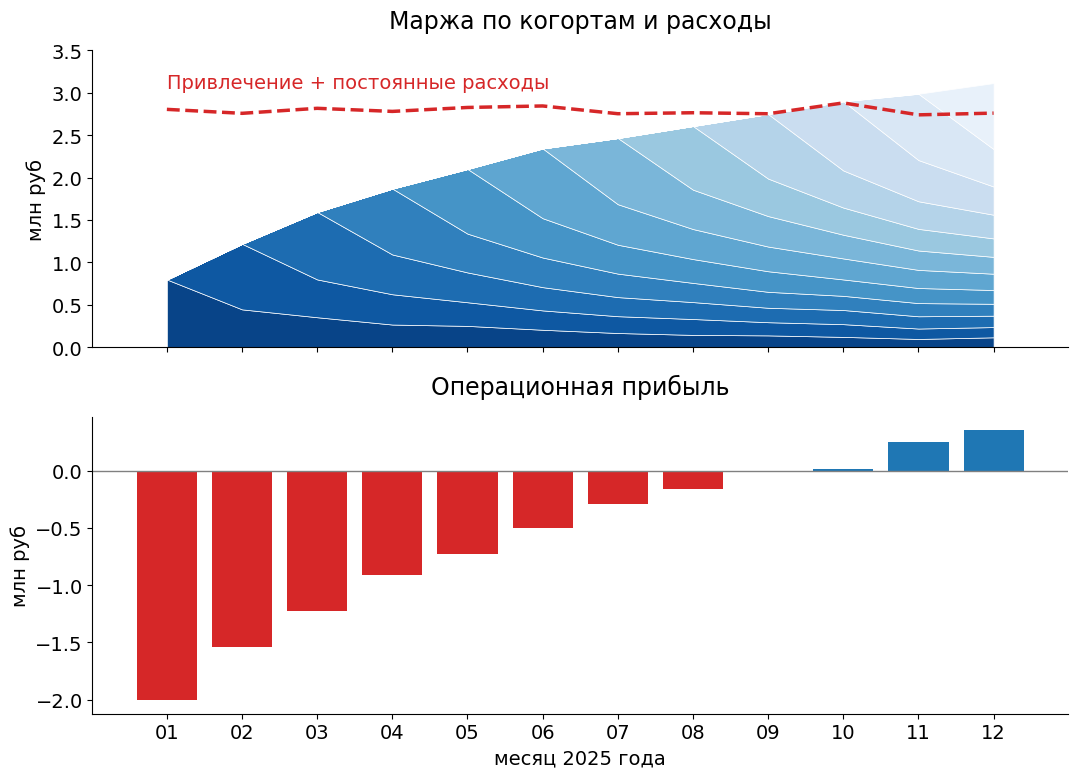

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].stackplot(range(12), layers.to_numpy() / 1e6, colors=sns.color_palette('Blues_r', 12), edgecolor='white', linewidth=0.5)
axes[0].plot(range(12), (pnl.acquisition + pnl.fixed) / 1e6, color='#d62728', lw=2.5, ls='--')
axes[0].text(0, 3.05, 'Привлечение + постоянные расходы', color='#d62728')
axes[0].set_title('Маржа по когортам и расходы')
axes[0].set_ylabel('млн руб'); axes[0].set_ylim(0, 3.5)

axes[1].bar(range(12), pnl.profit / 1e6, color=np.where(pnl.profit >= 0, '#1f77b4', '#d62728'))
axes[1].axhline(0, color='grey', lw=1)
axes[1].set_title('Операционная прибыль')
axes[1].set_ylabel('млн руб'); axes[1].set_xlabel('месяц 2025 года')
axes[1].set_xticks(range(12)); axes[1].set_xticklabels([m[-2:] for m in pnl.index])

plt.tight_layout(h_pad=0.8)
plt.show()

In [24]:
print(f'Прибыль за 2025 год: {pnl.profit.sum() / 1e6:.2f} млн руб')

Прибыль за 2025 год: -6.72 млн руб


**Компания закончила год с убытком 6.7 млн руб**, хотя LTV в 2.4 раза выше CAC.

- **Январь: убыток 2.0 млн руб.** Работает одна когорта: 0.8 млн маржи против 1.3 млн на привлечение и 1.5 млн постоянных расходов.
- **Каждый месяц добавляется слой.** Новая когорта приходит со своим минусом, но старые продолжают приносить маржу, и общая маржа растет с 0.8 до 3.1 млн руб в месяц.
- **В октябре маржа всех когорт впервые покрывает расходы.** С этого месяца компания прибыльна.
- **Накопленный убыток к этому моменту — 7.3 млн руб.** Это деньги, которые нужно было иметь, чтобы дожить до прибыли.

Противоречия нет. LTV — это деньги, растянутые на год, а привлечение и постоянные расходы оплачиваются сразу. Юнит-экономика говорит, что рост окупится; P&L показывает, когда и сколько денег на это нужно.

Месячная прибыль стала положительной в октябре. А когда компания вернет накопленный убыток? Данных за 2026 год у нас нет — нужен прогноз.

### LTV как инструмент решения

До сих пор мы считали бизнес в целом. Но решения принимают по частям: **какой канал масштабировать и сколько можно платить за пользователя?**

Для этого юнит-экономику считают по каналам: CAC канала сравнивают с LTV пользователей этого же канала. В таблице два варианта CAC:
- `cac_ad` — только реклама;
- `cac` — реклама и промокоды на первый заказ.

In [25]:
CHANNELS = ['organic', 'search_ads', 'social_ads', 'display_ads']
PAID = ['search_ads', 'social_ads', 'display_ads']
COLORS = {'organic': '#7f7f7f', 'search_ads': '#1f77b4', 'social_ads': '#2ca02c', 'display_ads': '#d62728'}

margin_ch = pd.DataFrame({ch: margin_by_age(df[df.channel == ch], df_users[df_users.channel == ch]) for ch in CHANNELS})
ltv_ch = margin_ch.cumsum()

n_users = df_users.groupby('channel').user_id.size()
ad_spend = df_costs.groupby('channel').ad_spend.sum()
promo_first = df.groupby('channel').promo_first_order.sum()

unit = pd.DataFrame({
    'n_users': n_users,
    'cac_ad': ad_spend / n_users,
    'cac': (ad_spend + promo_first) / n_users,
    'ltv_12': ltv_ch.loc[11],
}).loc[CHANNELS]
unit['ltv_12 / cac_ad'] = (unit.ltv_12 / unit.cac_ad).replace(np.inf, np.nan)
unit['ltv_12 / cac'] = (unit.ltv_12 / unit.cac).replace(np.inf, np.nan)

unit.round(2)

,n_users,cac_ad,cac,ltv_12,ltv_12 / cac_ad,ltv_12 / cac
organic,18465,0.00,0.00,799.02,NaN,NaN
search_ads,14355,414.87,475.11,985.50,2.38,2.07
social_ads,15475,276.44,377.40,413.97,1.50,1.10
display_ads,9638,110.63,291.10,221.29,2.00,0.76


- **search_ads** — лучший платный канал: за год пользователь приносит вдвое больше, чем стоил.
- **social_ads** окупается с небольшим запасом: 1.1.
- **display_ads** по полному CAC не окупается: 0.76.
- **Определение CAC меняет вывод.** У display_ads реклама стоит 111 руб, а полный CAC — 291 руб: 90% пользователей пришли по промокоду на первый заказ. По рекламному CAC канал выглядит прибыльным, с отношением 2.0.
- **Общий CAC этого не показывает.** На шаге 5 бизнес в целом выглядел здоровым: в среднем органика с нулевой стоимостью скрывает убыточный канал.

#### Ответ зависит от горизонта

Таблица посчитана за 12 месяцев. Но решение о бюджете принимают не раз в год. **Что мы увидели бы, если бы смотрели на канал раньше?**

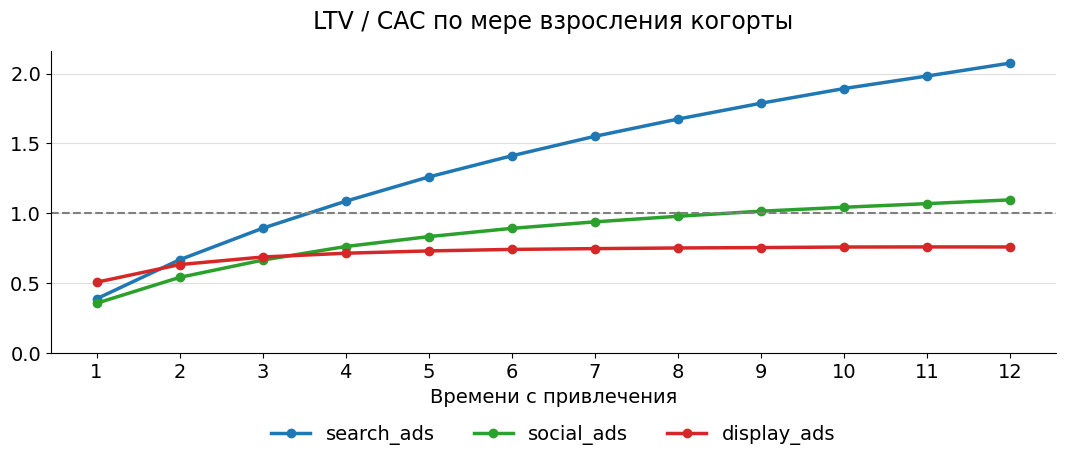

,3 мес,6 мес,8 мес,12 мес
search_ads,0.89,1.41,1.67,2.07
social_ads,0.67,0.89,0.98,1.10
display_ads,0.69,0.74,0.75,0.76


In [26]:
ratio = ltv_ch[PAID] / unit.cac[PAID]

fig, ax = plt.subplots(figsize=(11, 5))
for ch in PAID:
    ax.plot(ratio.index + 1, ratio[ch], marker='o', lw=2.5, color=COLORS[ch], label=ch)
ax.axhline(1, color='grey', lw=1.5, ls='--')
ax.set_title('LTV / CAC по мере взросления когорты')
ax.set_xlabel('Времени с привлечения'); ax.set_ylabel('')
ax.set_xticks(range(1, 13)); ax.set_ylim(0)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

by_horizon = ratio.loc[[2, 5, 7, 11]].T
by_horizon.columns = ['3 мес', '6 мес', '8 мес', '12 мес']
by_horizon.round(2)

- **search_ads** окупается на 4-м месяце и дальше только растет.
- **social_ads** окупается на 9-м месяце. Через полгода после привлечения канал выглядит убыточным: 0.89.
- **display_ads** останавливается на 0.76: кривая вышла на плато, пользователи ушли.

Через три месяца ни один канал еще не окупился: 0.89, 0.67 и 0.69. Убыточный display_ads на этом сроке выглядит не хуже social_ads. Вывод зависит от того, в какой момент мы смотрим.

#### Что будет дальше?

Пользователь живет в сервисе годами, а у нас 12 месяцев данных. Дальше кривые продолжатся, но как именно, в данных нет.

Откроем `df_truth`: ожидаемый LTV из генератора на пять лет вперед.

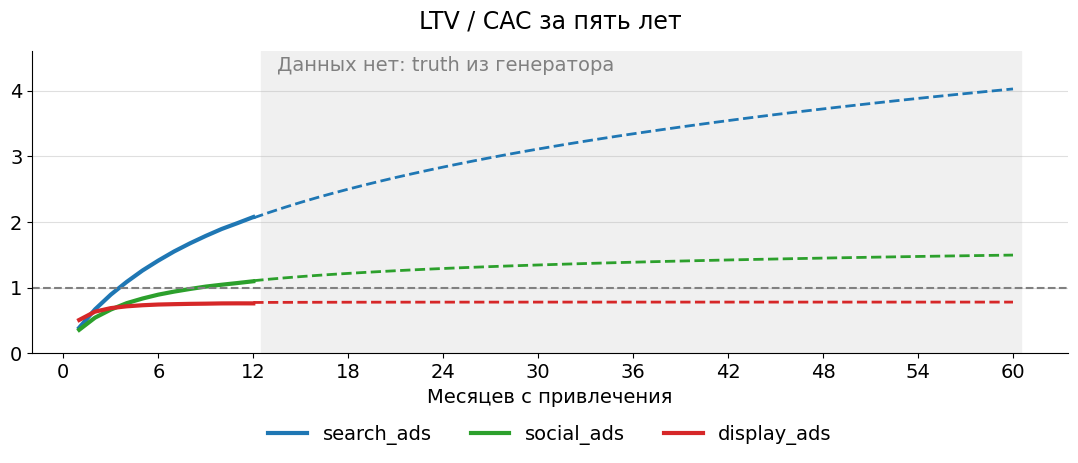

,3 мес,6 мес,8 мес,12 мес,36 мес (истина),60 мес (истина)
search_ads,0.89,1.41,1.67,2.07,3.34,4.02
social_ads,0.67,0.89,0.98,1.10,1.39,1.50
display_ads,0.69,0.74,0.75,0.76,0.78,0.78


In [32]:
truth_ratio = df_truth[PAID] / unit.cac[PAID]

fig, ax = plt.subplots(figsize=(11, 5))
ax.axvspan(12.5, 60.5, color='#f0f0f0')
for ch in PAID:
    ax.plot(ratio.index + 1, ratio[ch], lw=3, color=COLORS[ch], label=ch)
    ax.plot(truth_ratio.index[11:] + 1, truth_ratio[ch][11:], lw=2, ls='--', color=COLORS[ch])
ax.axhline(1, color='grey', lw=1.5, ls='--')
ax.text(13.5, 4.3, 'Данных нет: truth из генератора', color='grey')
ax.set_title('LTV / CAC за пять лет')
ax.set_xlabel('Месяцев с привлечения'); ax.set_ylabel('')
ax.set_xticks(range(0, 61, 6)); ax.set_ylim(0, 4.6)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

full = by_horizon.copy()
full['36 мес (истина)'] = truth_ratio.loc[35]
full['60 мес (истина)'] = truth_ratio.loc[59]
full.round(2)

- **search_ads:** за год 2.1, за три года 3.3, за пять лет 4.0. Годовой LTV показывает только половину ценности канала.
- **social_ads:** 1.1 за год и 1.5 за пять лет. Канал окупается, но медленно и с небольшим запасом.
- **display_ads:** 0.78 на любом горизонте. Ждать от этих пользователей больше нечего.

От горизонта зависит не только вывод окупается или нет, но и решение — **сколько можно платить за пользователя**. По годовому LTV допустимый CAC для search_ads — до 985 руб, по пятилетнему — почти вдвое больше.

В жизни `df_truth` нет. LTV на длинном горизонте всегда состоит из двух частей: **факт до возраста когорты и прогноз после него**.

#### Как получить LTV наперед

- **Продолжить когортную кривую.** К известным точкам маржи по возрастам подбирают убывающую функцию и продолжают ее на нужный горизонт. Есть и вероятностные модели, которые описывают уход пользователей: sBG для подписок и BG/NBD для продуктов без подписки (авторы
Fader, Hardie).
- **Взять форму кривой у старых когорт или похожего канала.** Для новой когорты известны первые месяцы; дальнейшую форму берут у когорт, которые уже прожили нужный срок.
- **Предсказывать по ранним сигналам.** Удержание первого и второго месяца, число заказов в первые недели — это прокси-метрики из лекции 3. По ним строят модель, которая предсказывает LTV пользователя вскоре после привлечения.
- **Проверять любой способ на прошлом.** Берем данные, известные полгода назад, делаем прогноз и сравниваем с тем, что произошло. Без такой проверки прогнозу верить нельзя.
- **Пересчитывать диапазон.** Чем старше самая взрослая когорта, тем точнее прогноз. Рядом с числом указывают, на скольких месяцах данных оно построено.
- **Выбирать горизонт под решение.** LTV «за всю жизнь» нужен редко. Обычно вопрос звучит так: окупится ли пользователь за срок, который компания готова ждать. Чем короче горизонт, тем меньше в LTV прогноза и больше факта.
- **Дисконтировать длинные горизонты.** На трех годах будущий рубль заметно дешевле сегодняшнего.

Для нового канала, по которому данных нет совсем, начинают с небольшого бюджета и решают о масштабе, когда первая когорта доживет до срока окупаемости похожих каналов.

### Когда компания вернет убыток

Вернемся к P&L. Месячная прибыль стала положительной в октябре, но накопленный убыток еще не возвращен, и для ответа нужен 2026 год.

Продолжим P&L по кривым из `df_truth`. В жизни на этом месте стоял бы прогноз. Допущения: каждый месяц приходит столько же пользователей, сколько в среднем в 2025-м, CAC и постоянные расходы не меняются.

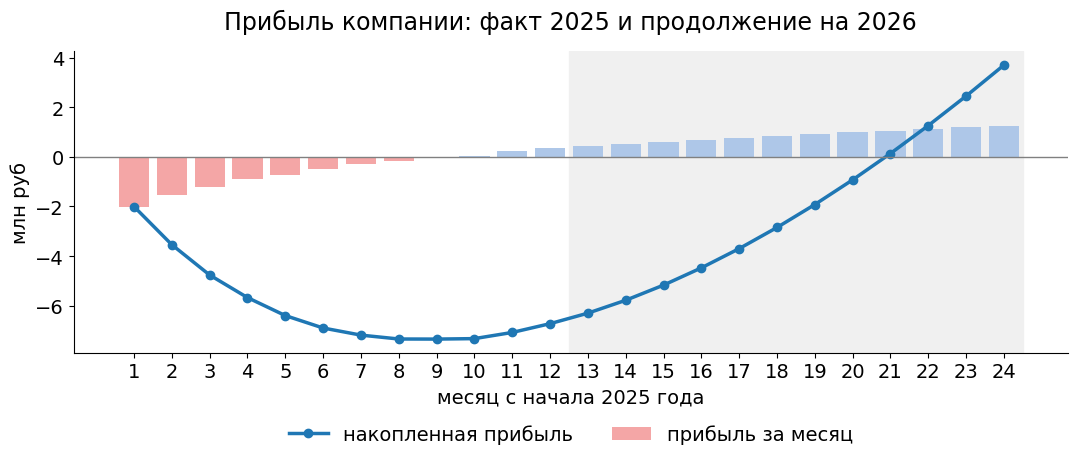

In [30]:
HORIZON = 24                                             

truth_margin = df_truth.diff().fillna(df_truth.iloc[0])

margin_fc, acquisition_fc = np.zeros(HORIZON), np.zeros(HORIZON)
for ch in CHANNELS:
    sizes = df_users[df_users.channel == ch].groupby('cohort_month').user_id.size().to_numpy()
    sizes = np.concatenate([sizes, np.full(12, sizes.mean())])

    curve = truth_margin[ch].to_numpy()
    for c in range(HORIZON):
        margin_fc[c:] += sizes[c] * curve[:HORIZON - c]
    acquisition_fc += sizes * unit.cac[ch]

profit = margin_fc - acquisition_fc - FIXED_COSTS
profit[:12] = pnl.profit.to_numpy()                    
cumulative = profit.cumsum()

fig, ax = plt.subplots(figsize=(11, 5))
ax.axvspan(11.5, 23.5, color='#f0f0f0')
ax.bar(range(HORIZON), profit / 1e6, color=np.where(profit >= 0, '#aec7e8', '#f4a6a6'), label='прибыль за месяц')
ax.plot(range(HORIZON), cumulative / 1e6, lw=2.5, marker='o', color='#1f77b4', label='накопленная прибыль')
ax.axhline(0, color='grey', lw=1)
ax.set_title('Прибыль компании: факт 2025 и продолжение на 2026')
ax.set_ylabel('млн руб'); ax.set_xlabel('месяц с начала 2025 года')
ax.set_xticks(range(HORIZON)); ax.set_xticklabels(range(1, HORIZON + 1))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

In [31]:
positive = np.flatnonzero(cumulative > 0)
print(f'Первый прибыльный месяц: {np.argmax(profit > 0) + 1}')
print(f'Максимальный накопленный убыток: {cumulative.min() / 1e6:.1f} млн руб, месяц {cumulative.argmin() + 1}')
print('Накопленная прибыль выходит в плюс: ' + (f'месяц {positive[0] + 1}' if len(positive) else 'позже 2026 года'))

Первый прибыльный месяц: 10
Максимальный накопленный убыток: -7.3 млн руб, месяц 9
Накопленная прибыль выходит в плюс: месяц 21


- **Сентябрь 2025, месяц 9:** накопленный убыток достигает максимума — 7.3 млн руб.
- **Октябрь 2025, месяц 10:** месячная прибыль становится положительной.
- **Сентябрь 2026, месяц 21:** накопленная прибыль выходит в плюс.

Пользователь окупается за 3 месяца, а компания — за 21. Разницу дают постоянные расходы и то, что привлечение не останавливается: каждая новая когорта начинает с минуса.

Если компания увеличит закупку, убыток вернется: расходы на привлечение вырастут сразу, а маржа новых когорт придет позже.

### Саммари

- **LTV считается по когортам и по марже.** В знаменателе — привлеченные пользователи тех когорт, которые дожили до возраста. Деление на всех пользователей занижает LTV.
- **Положительная юнит-экономика не означает прибыль.** LTV приходит по частям, CAC и постоянные расходы платятся сразу. Пользователь окупился за 3 месяца, компания — за 21.
- **CAC и LTV сравнивают внутри одного канала.** Общий CAC скрывает убыточные каналы, а рекламный CAC без промокодов занижает цену привлечения.
- **Вывод зависит от горизонта.** Канал, убыточный через полгода, может окупаться через год; годовой LTV лучшего канала показывает половину его ценности.
- **LTV для решений — это факт плюс прогноз.** Любой способ прогноза проверяют на прошлых когортах и пересчитывают по мере их взросления.